# EoMA Group B — Data & EDA
Milestone 1 scaffold: dataset audit, EDA, and a shared stratified split proposal.
Dataset: Kaggle Chest X-Ray Images (Pneumonia)
  - 5,863 JPEGs, classes NORMAL / PNEUMONIA.
  
Outputs go to results/ as small CSVs (group convention).

In [8]:
!pip install numpy pandas matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [10]:
from pathlib import Path
import random
import numpy as np, pandas as pd
from PIL import Image

DATA_ROOT = Path('chest_xray')  # point at the extracted Kaggle folder
SEED = 42
random.seed(SEED); np.random.seed(SEED)
assert DATA_ROOT.exists(), f'Dataset not found at {DATA_ROOT} — download from Kaggle first'

## 1. Inventory & integrity
Count files per split/class, flag unreadable images. Expected ballpark: train 5,216 / test 624 / val 16.

In [ ]:
rows, corrupted = [], []
for dataset_key in ['train', 'test', 'val']:
    for clazz in ['NORMAL', 'PNEUMONIA']:
        dataset_folder = DATA_ROOT / dataset_key / clazz
        data_files = sorted(dataset_folder.glob('*.jpeg')) + sorted(dataset_folder.glob('*.jpg')) if dataset_folder.exists() else []
        for data_file in data_files:
            try:
                with Image.open(data_file) as img:
                    w, h = img.size; mode = img.mode
                rows.append({'split': dataset_key, 'class': clazz, 'path': str(data_file), 'width': w, 'height': h, 'mode': mode})
            except Exception:
                corrupted.append(str(data_file))
df = pd.DataFrame(rows)
print('corrupt/unreadable:', len(corrupted), corrupted[:5])
df.groupby(['split', 'class']).size().unstack(fill_value=0) # print NORMLAL/PNEUMONIA counts per split

corrupt/unreadable: 0 []


class,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


## 2. Class balance & image properties
Check the NORMAL:PNEUMONIA ratio (~1:3 expected), size spread, and brightness stats on a sample.

In [ ]:
def brightness(p):
    with Image.open(p) as im:
        return float(np.asarray(im.convert('L'), # convert to grayscale
                                dtype=np.float32).mean())

print('class distribution per split')
print((df.groupby('split')['class']
       .value_counts(normalize=True).unstack() * 100)
       .round(1)
       )
print()
print('image size distribution per class')
print(df.groupby('class')[['width', 'height']]
      .describe()
      .round(1)
      )

sample = df.sample(min(300, len(df)), random_state=SEED) # sample 300 images for brightness distribution analysis

print()
print('brightness distribution per class')
# check pulmonary infiltration
sample = sample.assign(brightness=sample['path'].map(brightness))
sample.groupby('class')['brightness'].describe().round(1) # plot brightness distribution per class
# 

class distribution per split
class  NORMAL  PNEUMONIA
split                   
test     37.5       62.5
train    25.7       74.3
val      50.0       50.0

image size distribution per class
            width                                                        \
            count    mean    std    min     25%     50%     75%     max   
class                                                                     
NORMAL     1583.0  1686.4  305.3  912.0  1472.0  1654.0  1848.0  2916.0   
PNEUMONIA  4273.0  1195.1  285.1  384.0  1000.0  1160.0  1360.0  2772.0   

           height                                                        
            count    mean    std    min     25%     50%     75%     max  
class                                                                    
NORMAL     1583.0  1378.6  343.0  496.0  1140.0  1323.0  1554.0  2713.0  
PNEUMONIA  4273.0   819.6  270.9  127.0   640.0   776.0   960.0  2304.0  

brightness distribution per class


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
NORMAL,76.0,121.4,13.4,86.4,114.3,122.1,129.5,159.6
PNEUMONIA,224.0,123.7,18.0,76.1,112.2,123.4,135.3,166.7


## 3. Sample grid
For eyeball check: Plot 4 NORMAL + 4 PNEUMONIA samples; note any mislabelled or artefacts-looking cases for the EDA notes.

display sample images per class (NORMAL vs PNEUMONIA)


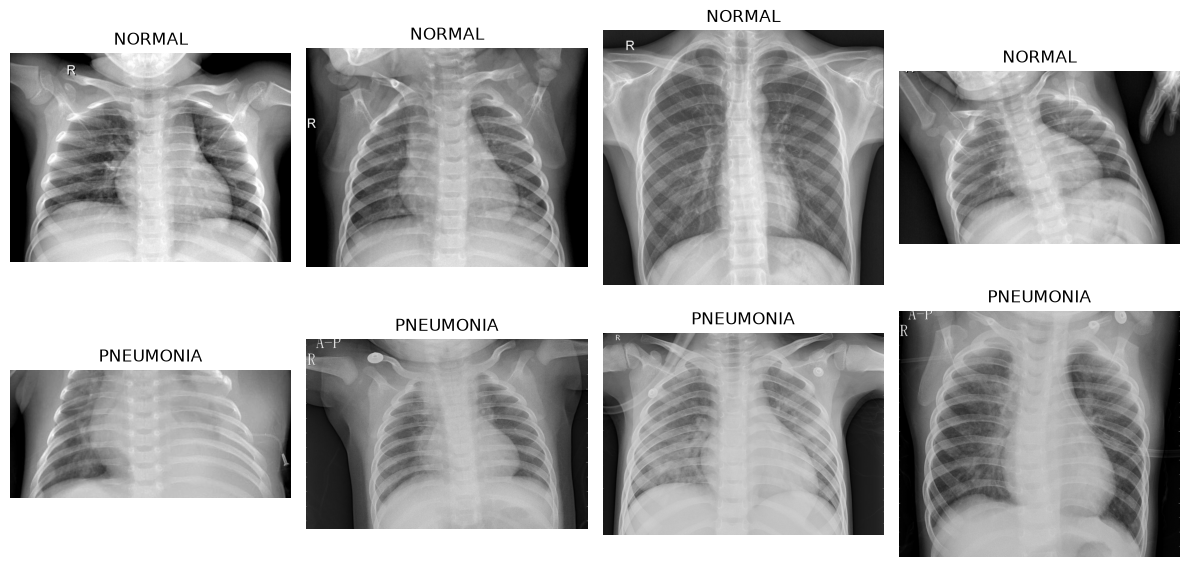

In [ ]:
import matplotlib.pyplot as plt

print('display sample images per class (NORMAL vs PNEUMONIA)')
_, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, clazz in zip(axes, ['NORMAL', 'PNEUMONIA']):
    picks = df[df['class'] == clazz].sample(4, random_state=SEED)['path'] # pick 4 random images per class
    for a, p in zip(ax, picks):
        with Image.open(p) as img:
            a.imshow(img.convert('L'), cmap='gray') # convert to grayscale for display
            a.set_title(clazz); a.axis('off')
plt.tight_layout(); plt.show()

## 4. Shared split proposal
The provided val split is only 16 images — unusable for tuning.

Proposal: keep `test` untouched for final evaluation only; carve a stratified val from `train` (85/15, seed 42) that ALL members use, so model comparisons share one yardstick. This cell will save the split as CSV to results/ and commit it — filenames only.

In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

train_df = df[df['split'] == 'train'].reset_index(drop=True)
# randomly split 15% of the training set for validation, stratified by class
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
# sss.split() returns (train_idx, test_idx), we only need the test idx
# sss.split() needs whole dataset and labels, so we pass train_df and train_df['class'] to it
_, validation_idx = next(sss.split(train_df, train_df['class']))
# if index of train_df is in validation_idx, assign 'val_shared', else 'train_shared'
split_df = train_df.assign(partition=np.where(train_df.index.isin(validation_idx), 'val_shared', 'train_shared'))
print('train/val_shared split distribution')
print(split_df
      .groupby(['partition', 'class']).size().unstack(fill_value=0)
      )
print()

Path('results').mkdir(exist_ok=True)
split_df[['path', 'class', 'partition']].to_csv('results/split.csv', index=False)
counts = df.groupby(['split', 'class']).size().unstack(fill_value=0) # NORMLAL/PNEUMONIA counts per split
counts.to_csv('results/dataset_inventory.csv')
print('saved results/split.csv + results/dataset_inventory.csv')

train/val_shared split distribution
class         NORMAL  PNEUMONIA
partition                      
train_shared    1140       3293
val_shared       201        582

saved results/shared_split_seed42.csv + results/dataset_inventory.csv


## 5. Preprocessing / augmentation notes (to confirm with the group)
- Resize: pick ONE input size for all experiments (e.g. 224x224).
- Normalisation: record mean/std source (ImageNet vs dataset-computed) so that the baseline's choice matches.
- Augmentation caution: horizontal flip changes heart laterality on chest X-rays